In [3]:

# ==========================================
# PROJETO: CIÊNCIA DE DADOS E IA - VENDAS
# ETAPA 1: CRIAÇÃO DA BASE DE DADOS
# ==========================================

import pandas as pd
import numpy as np

# 1. Garantir resultados reproduzíveis
np.random.seed(42)

# 2. Definir os produtos e seus preços
produtos = {
    "Notebook": {"categoria": "Eletrônicos", "preco": 3500},
    "Mouse": {"categoria": "Acessórios", "preco": 80},
    "Teclado": {"categoria": "Acessórios", "preco": 150},
    "Monitor": {"categoria": "Eletrônicos", "preco": 1200},
    "Impressora": {"categoria": "Escritório", "preco": 900},
    "Cadeira": {"categoria": "Móveis", "preco": 750},
    "Webcam": {"categoria": "Acessórios", "preco": 250},
    "Headset": {"categoria": "Acessórios", "preco": 180},
    "Tablet": {"categoria": "Eletrônicos", "preco": 1800},
    "Mesa": {"categoria": "Móveis", "preco": 650}
}

# 3. Definir o tamanho da base
n = 1000

# 4. Sortear os produtos vendidos
lista_produtos = np.random.choice(
    list(produtos.keys()), size=n
)

# 5. Criar as datas das vendas
datas = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2026-09-30"),
        size=n
    )
)

# 6. Montar a tabela de vendas
df = pd.DataFrame({
    "id_venda": range(1, n + 1),
    "data": datas,
    "produto": lista_produtos,
    "quantidade": np.random.randint(1, 9, size=n),
    "regiao": np.random.choice(
        ["Norte", "Nordeste", "Centro-Oeste",
         "Sudeste", "Sul"], size=n
    ),
    "canal": np.random.choice(
        ["Loja física", "Site", "Marketplace"],
        size=n, p=[0.40, 0.35, 0.25]
    ),
    "pagamento": np.random.choice(
        ["Pix", "Cartão de crédito",
         "Cartão de débito", "Boleto"],
        size=n
    ),
    "tipo_cliente": np.random.choice(
        ["Novo", "Recorrente"],
        size=n, p=[0.35, 0.65]
    )
})

# 7. Adicionar categoria e preço conforme o produto
df["categoria"] = df["produto"].map(
    lambda p: produtos[p]["categoria"]
)

df["preco_unitario"] = df["produto"].map(
    lambda p: produtos[p]["preco"]
).astype(float)

# 8. Simular descontos comerciais
df["desconto_pct"] = np.random.choice(
    [0, 0.05, 0.10, 0.15, 0.20],
    size=n,
    p=[0.40, 0.25, 0.20, 0.10, 0.05]
)

# 9. Calcular o valor total da venda
df["faturamento"] = (
    df["quantidade"]
    * df["preco_unitario"]
    * (1 - df["desconto_pct"])
).round(2)

# 10. Introduzir alguns problemas controlados
# para praticarmos a limpeza nas próximas etapas.
indices = np.random.choice(df.index, size=5, replace=False)
df.loc[indices, "regiao"] = np.nan

indices_preco = np.random.choice(
    df.index, size=3, replace=False
)
df.loc[indices_preco, "preco_unitario"] = np.nan

# Inserir 5 registros duplicados intencionalmente
df = pd.concat(
    [df, df.sample(n=5, random_state=42)],
    ignore_index=True
)

# 11. Salvar a base como arquivo CSV
df.to_csv("vendas_ficticias.csv", index=False)

# 12. Exibir uma confirmação
print("Base de dados criada com sucesso!")
print("Arquivo: vendas_ficticias.csv")
print("Dimensões da base:", df.shape)

display(df.head(10))


Base de dados criada com sucesso!
Arquivo: vendas_ficticias.csv
Dimensões da base: (1005, 12)


,id_venda,data,produto,quantidade,regiao,canal,pagamento,tipo_cliente,categoria,preco_unitario,desconto_pct,faturamento
0,1,2026-09-15,Webcam,7,Norte,Marketplace,Cartão de débito,Novo,Acessórios,250.0,0.15,1487.5
1,2,2026-09-08,Monitor,6,Sudeste,Loja física,Cartão de crédito,Novo,Eletrônicos,1200.0,0.00,7200.0
2,3,2026-04-05,Headset,4,Centro-Oeste,Site,Cartão de crédito,Recorrente,Acessórios,180.0,0.05,684.0
3,4,2025-12-22,Impressora,8,Norte,Marketplace,Cartão de crédito,Recorrente,Escritório,900.0,0.15,6120.0
4,5,2025-11-20,Webcam,6,Sul,Site,Cartão de crédito,Novo,Acessórios,250.0,0.05,1425.0
5,6,2025-05-13,Mesa,4,Sul,Loja física,Cartão de crédito,Recorrente,Móveis,650.0,0.10,2340.0
6,7,2025-05-07,Teclado,2,Sul,Marketplace,Pix,Recorrente,Acessórios,150.0,0.00,300.0
7,8,2025-04-16,Webcam,4,Sul,Site,Pix,Novo,Acessórios,250.0,0.00,1000.0
8,9,2026-08-27,Headset,5,Nordeste,Loja física,Pix,Novo,Acessórios,180.0,0.05,855.0
9,10,2026-01-13,Impressora,5,Sudeste,Site,Cartão de débito,Novo,Escritório,900.0,0.00,4500.0


In [4]:

# ETAPA 1.2 - PRIMEIRA INSPEÇÃO

# Visualizar as primeiras linhas
display(df.head())

# Ver o número de linhas e colunas
print("Dimensões:", df.shape)

# Listar os nomes das colunas
print("\nColunas:")
print(df.columns.tolist())

# Ver os tipos de dados e valores não nulos
print("\nInformações da base:")
df.info()

# Ver estatísticas das colunas numéricas
print("\nEstatísticas:")
display(df.describe())

# Verificar valores ausentes
print("\nValores ausentes por coluna:")
display(df.isnull().sum())

# Contar registros duplicados
print("\nLinhas duplicadas:", df.duplicated().sum())


,id_venda,data,produto,quantidade,regiao,canal,pagamento,tipo_cliente,categoria,preco_unitario,desconto_pct,faturamento
0,1,2026-09-15,Webcam,7,Norte,Marketplace,Cartão de débito,Novo,Acessórios,250.0,0.15,1487.5
1,2,2026-09-08,Monitor,6,Sudeste,Loja física,Cartão de crédito,Novo,Eletrônicos,1200.0,0.00,7200.0
2,3,2026-04-05,Headset,4,Centro-Oeste,Site,Cartão de crédito,Recorrente,Acessórios,180.0,0.05,684.0
3,4,2025-12-22,Impressora,8,Norte,Marketplace,Cartão de crédito,Recorrente,Escritório,900.0,0.15,6120.0
4,5,2025-11-20,Webcam,6,Sul,Site,Cartão de crédito,Novo,Acessórios,250.0,0.05,1425.0


Dimensões: (1005, 12)

Colunas:
['id_venda', 'data', 'produto', 'quantidade', 'regiao', 'canal', 'pagamento', 'tipo_cliente', 'categoria', 'preco_unitario', 'desconto_pct', 'faturamento']

Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_venda        1005 non-null   int64         
 1   data            1005 non-null   datetime64[ns]
 2   produto         1005 non-null   object        
 3   quantidade      1005 non-null   int64         
 4   regiao          1000 non-null   object        
 5   canal           1005 non-null   object        
 6   pagamento       1005 non-null   object        
 7   tipo_cliente    1005 non-null   object        
 8   categoria       1005 non-null   object        
 9   preco_unitario  1002 non-null   float64       
 10  desconto_pct    1005 non-null   float64       
 11  fa

,id_venda,data,quantidade,preco_unitario,desconto_pct,faturamento
count,1005.000000,1005,1005.000000,1002.000000,1005.000000,1005.000000
mean,501.068657,2025-11-07 07:52:50.149253632,4.571144,994.600798,0.056667,4297.765174
min,1.000000,2025-01-01 00:00:00,1.000000,80.000000,0.000000,64.000000
25%,252.000000,2025-06-01 00:00:00,3.000000,180.000000,0.000000,750.000000
50%,502.000000,2025-11-07 00:00:00,5.000000,750.000000,0.050000,2040.000000
75%,749.000000,2026-04-12 00:00:00,7.000000,1200.000000,0.100000,5700.000000
max,1000.000000,2026-09-30 00:00:00,8.000000,3500.000000,0.200000,28000.000000
std,288.355045,NaN,2.276277,1042.907874,0.059758,5388.763812



Valores ausentes por coluna:


,0
id_venda,0
data,0
produto,0
quantidade,0
regiao,5
canal,0
pagamento,0
tipo_cliente,0
categoria,0
preco_unitario,3



Linhas duplicadas: 5


In [5]:

# Duplicatas considerando todas as colunas
duplicatas_completas = df.duplicated().sum()

# Duplicatas de identificador
duplicatas_id = df["id_venda"].duplicated().sum()

print("Linhas completamente duplicadas:", duplicatas_completas)
print("IDs de venda repetidos:", duplicatas_id)

# Mostrar as linhas completamente duplicadas
display(
    df[df.duplicated(keep=False)]
    .sort_values("id_venda")
)


Linhas completamente duplicadas: 5
IDs de venda repetidos: 5


,id_venda,data,produto,quantidade,regiao,canal,pagamento,tipo_cliente,categoria,preco_unitario,desconto_pct,faturamento
411,412,2026-03-30,Tablet,2,Norte,Site,Pix,Novo,Eletrônicos,1800.0,0.00,3600.0
1004,412,2026-03-30,Tablet,2,Norte,Site,Pix,Novo,Eletrônicos,1800.0,0.00,3600.0
1000,522,2026-04-04,Impressora,5,Nordeste,Site,Cartão de crédito,Recorrente,Escritório,900.0,0.05,4275.0
521,522,2026-04-04,Impressora,5,Nordeste,Site,Cartão de crédito,Recorrente,Escritório,900.0,0.05,4275.0
1003,661,2025-12-19,Impressora,1,Norte,Site,Cartão de crédito,Recorrente,Escritório,900.0,0.15,765.0
660,661,2025-12-19,Impressora,1,Norte,Site,Cartão de crédito,Recorrente,Escritório,900.0,0.15,765.0
737,738,2025-04-17,Headset,1,Norte,Loja física,Cartão de crédito,Recorrente,Acessórios,180.0,0.05,171.0
1001,738,2025-04-17,Headset,1,Norte,Loja física,Cartão de crédito,Recorrente,Acessórios,180.0,0.05,171.0
1002,741,2025-11-01,Monitor,4,Sudeste,Site,Pix,Recorrente,Eletrônicos,1200.0,0.00,4800.0
740,741,2025-11-01,Monitor,4,Sudeste,Site,Pix,Recorrente,Eletrônicos,1200.0,0.00,4800.0


In [6]:

# Verificações de consistência
problemas = {
    "quantidade_zero_ou_negativa":
        df["quantidade"].le(0).sum(),

    "preco_negativo":
        df["preco_unitario"].lt(0).sum(),

    "desconto_fora_do_intervalo":
        (~df["desconto_pct"].between(0, 1)).sum(),

    "faturamento_negativo":
        df["faturamento"].lt(0).sum(),

    "data_fora_do_periodo":
        (~df["data"].between(
            "2025-01-01", "2026-09-30"
        )).sum()
}

display(
    pd.DataFrame.from_dict(
        problemas,
        orient="index",
        columns=["quantidade_de_ocorrencias"]
    )
)

# Verificar se o faturamento corresponde à fórmula esperada
faturamento_calculado = (
    df["quantidade"]
    * df["preco_unitario"]
    * (1 - df["desconto_pct"])
).round(2)

divergencias = (
    df["faturamento"].notna()
    & faturamento_calculado.notna()
    & ~np.isclose(
        df["faturamento"],
        faturamento_calculado,
        atol=0.01
    )
)

print(
    "Divergências no cálculo do faturamento:",
    divergencias.sum()
)


,quantidade_de_ocorrencias
quantidade_zero_ou_negativa,0
preco_negativo,0
desconto_fora_do_intervalo,0
faturamento_negativo,0
data_fora_do_periodo,0


Divergências no cálculo do faturamento: 0


In [ ]:

from google.colab import files

files.download("vendas_ficticias.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

relatorio_qualidade = pd.DataFrame({
    "indicador": [
        "Total de linhas",
        "Total de colunas",
        "Linhas duplicadas completas",
        "IDs de venda repetidos",
        "Total de células ausentes",
        "Preços ausentes",
        "Regiões ausentes"
    ],
    "resultado": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int(df["id_venda"].duplicated().sum()),
        int(df.isna().sum().sum()),
        int(df["preco_unitario"].isna().sum()),
        int(df["regiao"].isna().sum())
    ]
})

display(relatorio_qualidade)

# Guardar o diagnóstico para consulta posterior
relatorio_qualidade.to_csv(
    "relatorio_qualidade_etapa2.csv",
    index=False
)


,indicador,resultado
0,Total de linhas,1005
1,Total de colunas,12
2,Linhas duplicadas completas,5
3,IDs de venda repetidos,5
4,Total de células ausentes,8
5,Preços ausentes,3
6,Regiões ausentes,5


In [8]:

import pandas as pd
import numpy as np

# Preservar a base original
df_bruto = df.copy(deep=True)

# Criar a base que será tratada
df_limpo = df_bruto.copy(deep=True)

print("Linhas na base original:", len(df_bruto))
print("Linhas na base de trabalho:", len(df_limpo))

print(
    "A base original permanece preservada:",
    df_bruto.equals(df)
)


Linhas na base original: 1005
Linhas na base de trabalho: 1005
A base original permanece preservada: True


In [9]:

# Contar as duplicatas antes da remoção
duplicatas_antes = df_limpo.duplicated().sum()

print("Duplicatas encontradas:", duplicatas_antes)

# Remover apenas linhas inteiramente duplicadas
df_limpo = df_limpo.drop_duplicates().copy()

# Conferir o resultado
print("Linhas após a remoção:", len(df_limpo))
print(
    "Duplicatas restantes:",
    df_limpo.duplicated().sum()
)


Duplicatas encontradas: 5
Linhas após a remoção: 1000
Duplicatas restantes: 0


In [10]:

# Catálogo de preços utilizado na criação da base
catalogo_precos = {
    "Notebook": 3500,
    "Mouse": 80,
    "Teclado": 150,
    "Monitor": 1200,
    "Impressora": 900,
    "Cadeira": 750,
    "Webcam": 250,
    "Headset": 180,
    "Tablet": 1800,
    "Mesa": 650
}

# Identificar preços ausentes antes do tratamento
precos_ausentes_antes = df_limpo[
    "preco_unitario"
].isna().sum()

# Recuperar o preço a partir do catálogo
precos_referencia = df_limpo["produto"].map(
    catalogo_precos
)

df_limpo["preco_unitario"] = (
    df_limpo["preco_unitario"]
    .fillna(precos_referencia)
)

print(
    "Preços ausentes antes:",
    precos_ausentes_antes
)
print(
    "Preços ausentes depois:",
    df_limpo["preco_unitario"].isna().sum()
)


Preços ausentes antes: 3
Preços ausentes depois: 0


In [11]:

# Contar os valores ausentes antes
regioes_ausentes_antes = df_limpo["regiao"].isna().sum()

# Registrar a ausência explicitamente
df_limpo["regiao"] = (
    df_limpo["regiao"]
    .fillna("Não informado")
)

print(
    "Regiões ausentes antes:",
    regioes_ausentes_antes
)
print(
    "Regiões não informadas após o tratamento:",
    (df_limpo["regiao"] == "Não informado").sum()
)


Regiões ausentes antes: 5
Regiões não informadas após o tratamento: 5


In [12]:

# Guardar o faturamento anterior para comparação
faturamento_anterior = df_limpo["faturamento"].copy()

# Recalcular o faturamento
df_limpo["faturamento"] = (
    df_limpo["quantidade"]
    * df_limpo["preco_unitario"]
    * (1 - df_limpo["desconto_pct"])
).round(2)

# Identificar registros cujo faturamento mudou
alteracoes_faturamento = (
    faturamento_anterior.isna()
    | ~np.isclose(
        faturamento_anterior.fillna(0),
        df_limpo["faturamento"].fillna(0),
        atol=0.01
    )
)

print(
    "Registros com faturamento alterado:",
    alteracoes_faturamento.sum()
)

display(
    df_limpo.loc[
        alteracoes_faturamento,
        [
            "id_venda", "produto", "quantidade",
            "preco_unitario", "desconto_pct",
            "faturamento"
        ]
    ].head(10)
)


Registros com faturamento alterado: 0


,id_venda,produto,quantidade,preco_unitario,desconto_pct,faturamento


In [13]:

# Diagnóstico após a limpeza
validacao = pd.DataFrame({
    "indicador": [
        "Linhas finais",
        "Duplicatas completas",
        "Preços ausentes",
        "Regiões ausentes",
        "Quantidades inválidas",
        "Preços negativos",
        "Descontos inválidos",
        "Faturamentos negativos"
    ],
    "resultado": [
        len(df_limpo),
        int(df_limpo.duplicated().sum()),
        int(df_limpo["preco_unitario"].isna().sum()),
        int(df_limpo["regiao"].isna().sum()),
        int(df_limpo["quantidade"].le(0).sum()),
        int(df_limpo["preco_unitario"].lt(0).sum()),
        int(
            (~df_limpo["desconto_pct"].between(0, 1)).sum()
        ),
        int(df_limpo["faturamento"].lt(0).sum())
    ]
})

display(validacao)

# Confirmar que a base bruta não foi alterada
print(
    "Base bruta preservada:",
    df_bruto.equals(df)
)


,indicador,resultado
0,Linhas finais,1000
1,Duplicatas completas,0
2,Preços ausentes,0
3,Regiões ausentes,0
4,Quantidades inválidas,0
5,Preços negativos,0
6,Descontos inválidos,0
7,Faturamentos negativos,0


Base bruta preservada: True


In [14]:

# Salvar a base tratada
df_limpo.to_csv(
    "vendas_tratadas.csv",
    index=False
)

# Criar um resumo das alterações
log_limpeza = pd.DataFrame({
    "operacao": [
        "Duplicatas completas removidas",
        "Preços recuperados do catálogo",
        "Regiões marcadas como não informadas",
        "Faturamento recalculado"
    ],
    "quantidade": [
        int(df_bruto.duplicated().sum()),
        int(precos_ausentes_antes),
        int(regioes_ausentes_antes),
        int(alteracoes_faturamento.sum())
    ]
})

log_limpeza.to_csv(
    "registro_limpeza.csv",
    index=False
)

display(log_limpeza)

print("Arquivos gerados:")
print("- vendas_tratadas.csv")
print("- registro_limpeza.csv")


,operacao,quantidade
0,Duplicatas completas removidas,5
1,Preços recuperados do catálogo,3
2,Regiões marcadas como não informadas,5
3,Faturamento recalculado,0


Arquivos gerados:
- vendas_tratadas.csv
- registro_limpeza.csv


In [ ]:

from google.colab import files

files.download("vendas_tratadas.csv")
files.download("registro_limpeza.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Se df_limpo ainda existir, podemos continuar.
# Caso contrário, carregue o arquivo salvo:
try:
    df_limpo
    print("Base tratada já está carregada.")
except NameError:
    from google.colab import files
    arquivos = files.upload()
    nome_arquivo = next(iter(arquivos))
    df_limpo = pd.read_csv(
        nome_arquivo,
        parse_dates=["data"]
    )

# Criar uma cópia exclusiva para análise
df_eda = df_limpo.copy()

print("Linhas:", len(df_eda))
print("Colunas:", len(df_eda.columns))

display(df_eda.head())


Base tratada já está carregada.
Linhas: 1000
Colunas: 12


,id_venda,data,produto,quantidade,regiao,canal,pagamento,tipo_cliente,categoria,preco_unitario,desconto_pct,faturamento
0,1,2026-09-15,Webcam,7,Norte,Marketplace,Cartão de débito,Novo,Acessórios,250.0,0.15,1487.5
1,2,2026-09-08,Monitor,6,Sudeste,Loja física,Cartão de crédito,Novo,Eletrônicos,1200.0,0.00,7200.0
2,3,2026-04-05,Headset,4,Centro-Oeste,Site,Cartão de crédito,Recorrente,Acessórios,180.0,0.05,684.0
3,4,2025-12-22,Impressora,8,Norte,Marketplace,Cartão de crédito,Recorrente,Escritório,900.0,0.15,6120.0
4,5,2025-11-20,Webcam,6,Sul,Site,Cartão de crédito,Novo,Acessórios,250.0,0.05,1425.0


In [16]:

# Indicadores gerais do negócio
faturamento_total = df_eda["faturamento"].sum()
quantidade_vendida = df_eda["quantidade"].sum()
ticket_medio = df_eda["faturamento"].mean()
numero_vendas = df_eda["id_venda"].nunique()

indicadores = pd.DataFrame({
    "Indicador": [
        "Faturamento total",
        "Unidades vendidas",
        "Número de vendas identificadas",
        "Faturamento médio por registro"
    ],
    "Valor": [
        faturamento_total,
        quantidade_vendida,
        numero_vendas,
        ticket_medio
    ]
})

display(indicadores.round(2))


,Indicador,Valor
0,Faturamento total,4305643.00
1,Unidades vendidas,4581.00
2,Número de vendas identificadas,1000.00
3,Faturamento médio por registro,4305.64


,faturamento,unidades,registros
produto,,,
Notebook,1731100.0,518,118
Tablet,749160.0,444,91
Monitor,527220.0,465,94
Impressora,407205.0,483,107
Mesa,309562.5,501,107
Cadeira,307312.5,432,96
Webcam,99537.5,423,94
Headset,74970.0,444,100
Teclado,73387.5,518,110


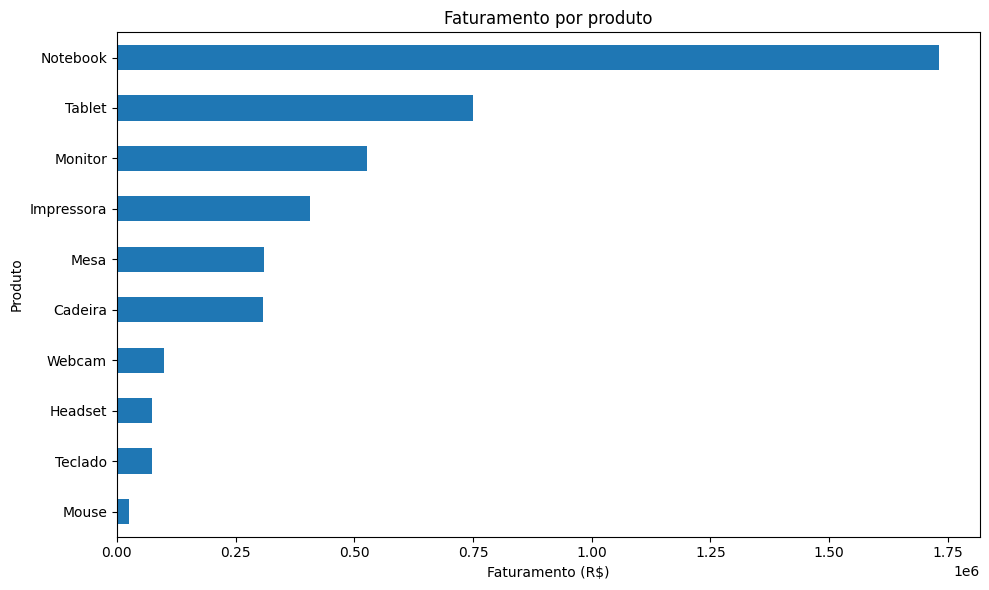

In [17]:

vendas_produto = (
    df_eda.groupby("produto")
    .agg(
        faturamento=("faturamento", "sum"),
        unidades=("quantidade", "sum"),
        registros=("id_venda", "count")
    )
    .sort_values("faturamento", ascending=False)
)

display(vendas_produto.round(2))

# Gráfico dos produtos com maior faturamento
vendas_produto["faturamento"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Faturamento por produto")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Produto")
plt.tight_layout()
plt.show()


,faturamento,unidades,participacao_pct
categoria,,,
Eletrônicos,3007480.0,1427,69.85
Móveis,616875.0,933,14.33
Escritório,407205.0,483,9.46
Acessórios,274083.0,1738,6.37


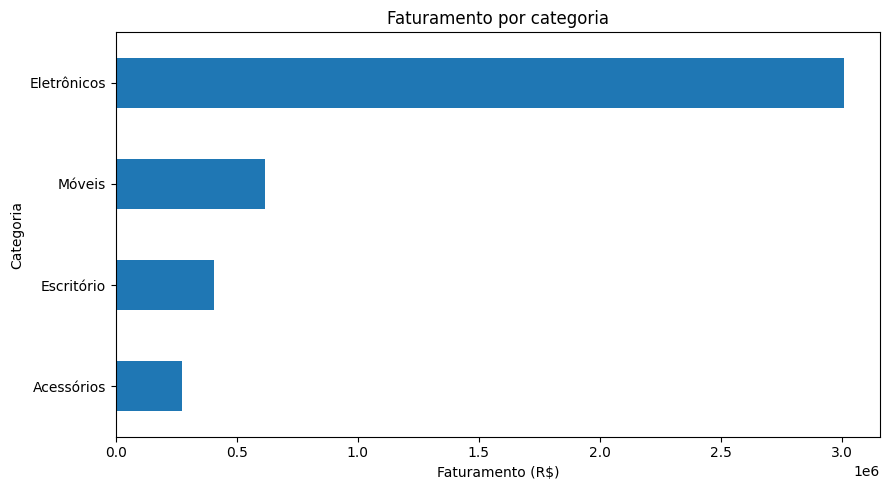

In [18]:

vendas_categoria = (
    df_eda.groupby("categoria")
    .agg(
        faturamento=("faturamento", "sum"),
        unidades=("quantidade", "sum")
    )
    .sort_values("faturamento", ascending=False)
)

vendas_categoria["participacao_pct"] = (
    vendas_categoria["faturamento"]
    / vendas_categoria["faturamento"].sum()
    * 100
)

display(vendas_categoria.round(2))

# Gráfico
vendas_categoria["faturamento"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Faturamento por categoria")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Categoria")
plt.tight_layout()
plt.show()


,faturamento,unidades,registros
regiao,,,
Norte,968085.5,921,203
Centro-Oeste,898538.0,954,209
Sul,893910.0,894,205
Sudeste,762704.5,965,209
Nordeste,756585.0,824,169
Não informado,25820.0,23,5


,faturamento,unidades,registros
canal,,,
Loja física,1710376.0,1855,409
Site,1586301.0,1620,349
Marketplace,1008966.0,1106,242


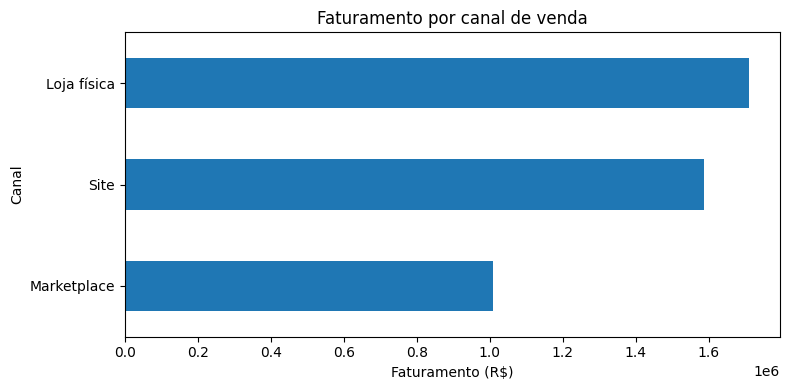

In [19]:

# Faturamento por região
vendas_regiao = (
    df_eda.groupby("regiao", dropna=False)
    .agg(
        faturamento=("faturamento", "sum"),
        unidades=("quantidade", "sum"),
        registros=("id_venda", "count")
    )
    .sort_values("faturamento", ascending=False)
)

display(vendas_regiao.round(2))

# Faturamento por canal
vendas_canal = (
    df_eda.groupby("canal")
    .agg(
        faturamento=("faturamento", "sum"),
        unidades=("quantidade", "sum"),
        registros=("id_venda", "count")
    )
    .sort_values("faturamento", ascending=False)
)

display(vendas_canal.round(2))

# Comparação visual dos canais
vendas_canal["faturamento"].sort_values().plot(
    kind="barh",
    figsize=(8, 4)
)

plt.title("Faturamento por canal de venda")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Canal")
plt.tight_layout()
plt.show()


,faturamento,unidades,registros
mes,,,
2025-01,274049.0,251,59
2025-02,199659.0,219,46
2025-03,288527.5,263,50
2025-04,200019.5,200,46
2025-05,201557.0,222,49
2025-06,187059.5,223,53
2025-07,203275.0,168,34
2025-08,252751.0,263,51
2025-09,166698.5,181,40


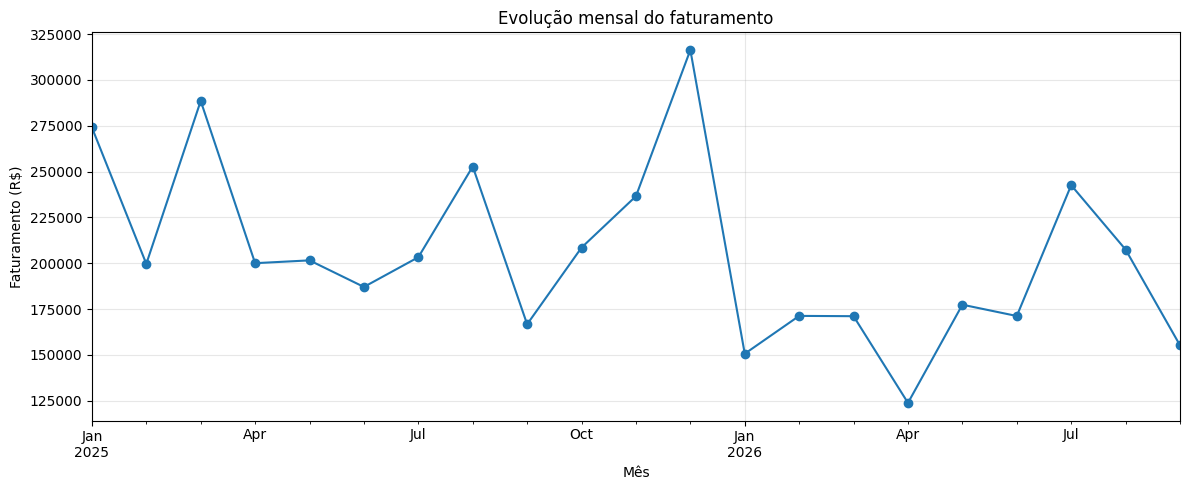

In [20]:

# Criar uma coluna de mês
df_eda["mes"] = (
    df_eda["data"]
    .dt.to_period("M")
)

# Agregar o faturamento por mês
vendas_mensais = (
    df_eda.groupby("mes")
    .agg(
        faturamento=("faturamento", "sum"),
        unidades=("quantidade", "sum"),
        registros=("id_venda", "count")
    )
    .sort_index()
)

display(vendas_mensais.round(2))

# Gráfico da evolução mensal
vendas_mensais["faturamento"].plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Evolução mensal do faturamento")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,quantidade,preco_unitario,desconto_pct,faturamento
quantidade,1.00,0.00,0.01,0.39
preco_unitario,0.00,1.00,-0.04,0.82
desconto_pct,0.01,-0.04,1.00,-0.10
faturamento,0.39,0.82,-0.10,1.00


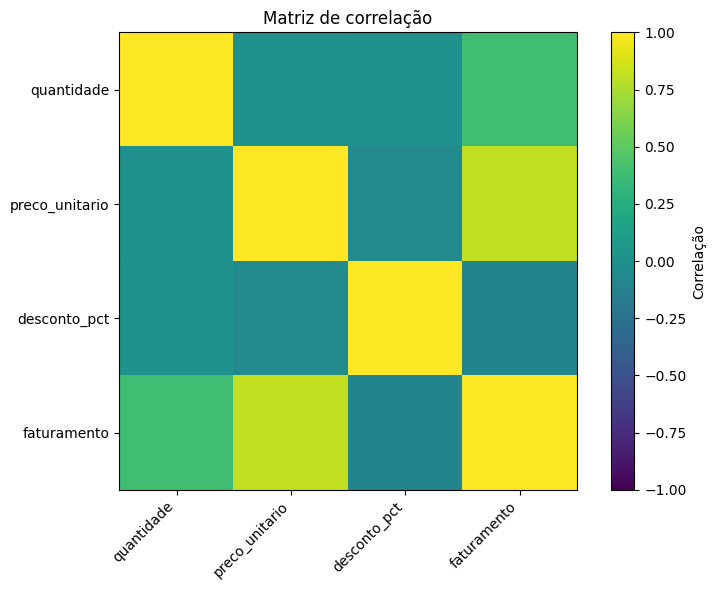

In [21]:

colunas_numericas = [
    "quantidade",
    "preco_unitario",
    "desconto_pct",
    "faturamento"
]

correlacoes = df_eda[colunas_numericas].corr()

display(correlacoes.round(2))

# Visualização da matriz de correlação
plt.figure(figsize=(8, 6))

plt.imshow(correlacoes, vmin=-1, vmax=1)
plt.colorbar(label="Correlação")

plt.xticks(
    range(len(correlacoes.columns)),
    correlacoes.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlacoes.index)),
    correlacoes.index
)

plt.title("Matriz de correlação")
plt.tight_layout()
plt.show()


In [22]:

produto_lider = vendas_produto["faturamento"].idxmax()
categoria_lider = vendas_categoria["faturamento"].idxmax()
regiao_lider = vendas_regiao["faturamento"].idxmax()
canal_lider = vendas_canal["faturamento"].idxmax()
mes_lider = vendas_mensais["faturamento"].idxmax()

print("===== RESUMO EXECUTIVO =====")
print(f"Faturamento total: R$ {faturamento_total:,.2f}")
print(f"Unidades vendidas: {quantidade_vendida:,}")
print(f"Produto com maior faturamento: {produto_lider}")
print(f"Categoria líder: {categoria_lider}")
print(f"Região líder: {regiao_lider}")
print(f"Canal líder: {canal_lider}")
print(f"Mês com maior faturamento: {mes_lider}")
print(
    "Faturamento do mês líder: "
    f"R$ {vendas_mensais.loc[mes_lider, 'faturamento']:,.2f}"
)


===== RESUMO EXECUTIVO =====
Faturamento total: R$ 4,305,643.00
Unidades vendidas: 4,581
Produto com maior faturamento: Notebook
Categoria líder: Eletrônicos
Região líder: Norte
Canal líder: Loja física
Mês com maior faturamento: 2025-12
Faturamento do mês líder: R$ 316,324.00


In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Recuperar a base, caso necessário
try:
    df_limpo
except NameError:
    from google.colab import files
    arquivos = files.upload()
    nome_arquivo = next(iter(arquivos))
    df_limpo = pd.read_csv(
        nome_arquivo,
        parse_dates=["data"]
    )

# Criar a série de faturamento mensal
df_modelo = df_limpo.copy()
df_modelo["data"] = pd.to_datetime(df_modelo["data"])

serie_mensal = (
    df_modelo
    .set_index("data")["faturamento"]
    .resample("MS")
    .sum()
)

# Garantir que os meses estejam em ordem
serie_mensal = serie_mensal.sort_index()

print("Quantidade de meses:", len(serie_mensal))
display(serie_mensal.to_frame("faturamento"))


Quantidade de meses: 21


,faturamento
data,
2025-01-01,274049.0
2025-02-01,199659.0
2025-03-01,288527.5
2025-04-01,200019.5
2025-05-01,201557.0
2025-06-01,187059.5
2025-07-01,203275.0
2025-08-01,252751.0
2025-09-01,166698.5


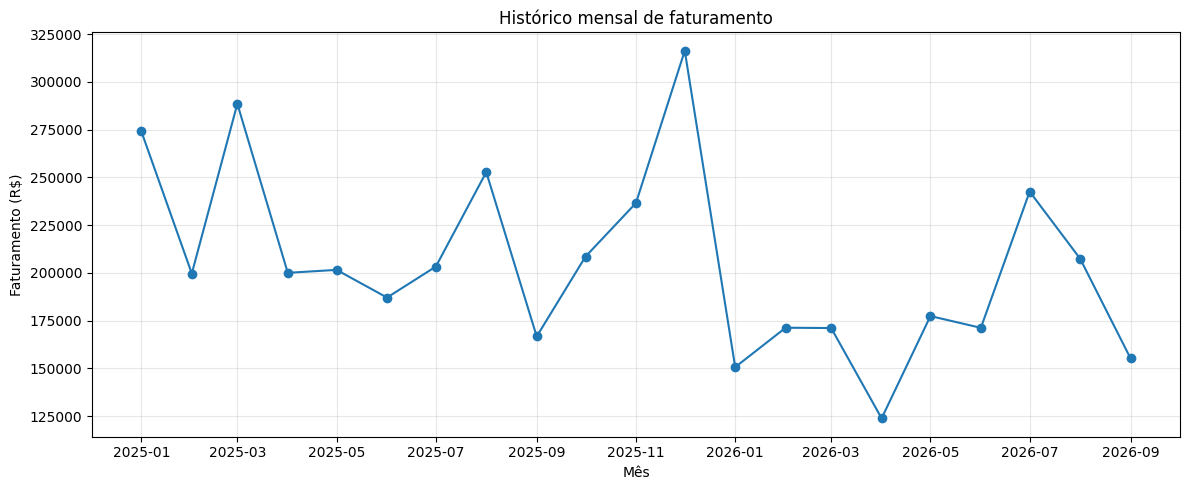

In [24]:

plt.figure(figsize=(12, 5))

plt.plot(
    serie_mensal.index,
    serie_mensal.values,
    marker="o"
)

plt.title("Histórico mensal de faturamento")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Remover valores ausentes, se existirem
serie_mensal = serie_mensal.dropna()

# Criar uma variável temporal numérica
dados_ml = pd.DataFrame({
    "data": serie_mensal.index,
    "faturamento": serie_mensal.values,
    "tempo": np.arange(len(serie_mensal))
})

# Exigir histórico mínimo para esta demonstração
if len(dados_ml) < 12:
    raise ValueError(
        "Precisamos de pelo menos 12 meses para esta demonstração."
    )

# Separação cronológica: meses iniciais para treino,
# meses finais para teste
ponto_corte = int(len(dados_ml) * 0.8)

treino = dados_ml.iloc[:ponto_corte].copy()
teste = dados_ml.iloc[ponto_corte:].copy()

X_treino = treino[["tempo"]]
y_treino = treino["faturamento"]

X_teste = teste[["tempo"]]
y_teste = teste["faturamento"]

print("Meses de treino:", len(treino))
print("Meses de teste:", len(teste))
print("Último mês de treino:", treino["data"].max().date())
print("Primeiro mês de teste:", teste["data"].min().date())


Meses de treino: 16
Meses de teste: 5
Último mês de treino: 2026-04-01
Primeiro mês de teste: 2026-05-01


In [26]:

# Criar e treinar o modelo
modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

# Prever os meses reservados para teste
previsoes = modelo.predict(X_teste)

# Comparar previsão e valor real
comparacao = pd.DataFrame({
    "mes": teste["data"].dt.strftime("%Y-%m").values,
    "faturamento_real": y_teste.values,
    "faturamento_previsto": previsoes
})

display(comparacao.round(2))


,mes,faturamento_real,faturamento_previsto
0,2026-05,177371.5,167258.58
1,2026-06,171212.0,162290.26
2,2026-07,242562.0,157321.94
3,2026-08,207446.5,152353.62
4,2026-09,155222.5,147385.30


In [27]:

# Métricas da regressão linear
mae_modelo = mean_absolute_error(y_teste, previsoes)

rmse_modelo = np.sqrt(
    mean_squared_error(y_teste, previsoes)
)

# Modelo de referência: repetir o último valor do treino
previsao_baseline = np.repeat(
    y_treino.iloc[-1],
    len(y_teste)
)

mae_baseline = mean_absolute_error(
    y_teste,
    previsao_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(y_teste, previsao_baseline)
)

metricas = pd.DataFrame({
    "modelo": [
        "Regressão Linear",
        "Referência: último mês"
    ],
    "MAE_R$": [
        mae_modelo,
        mae_baseline
    ],
    "RMSE_R$": [
        rmse_modelo,
        rmse_baseline
    ]
})

display(metricas.round(2))




,modelo,MAE_R$,RMSE_R$
0,Regressão Linear,33440.96,45922.51
1,Referência: último mês,66943.90,73747.69


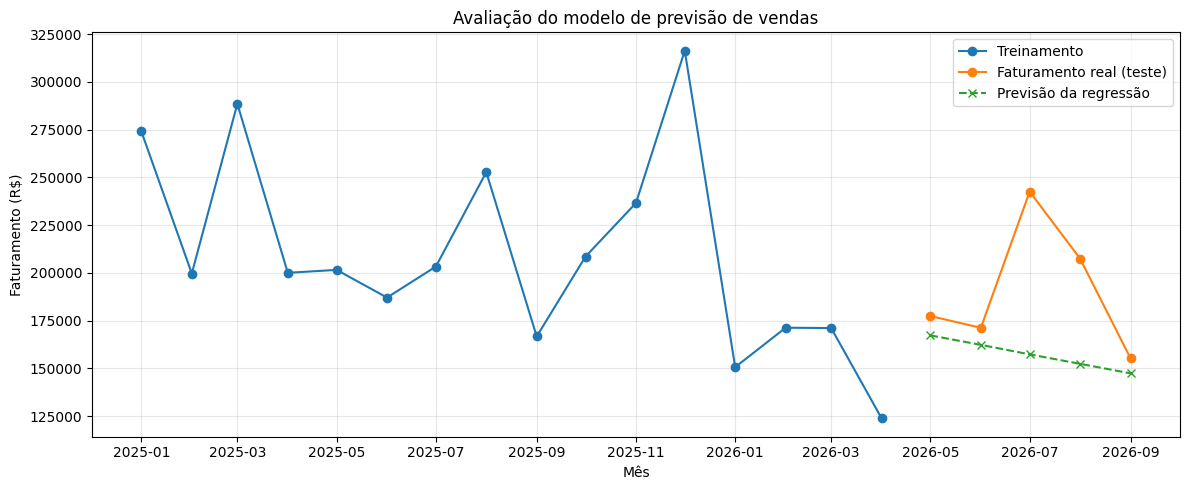

In [28]:

plt.figure(figsize=(12, 5))

plt.plot(
    treino["data"],
    y_treino,
    label="Treinamento",
    marker="o"
)

plt.plot(
    teste["data"],
    y_teste,
    label="Faturamento real (teste)",
    marker="o"
)

plt.plot(
    teste["data"],
    previsoes,
    label="Previsão da regressão",
    marker="x",
    linestyle="--"
)

plt.title("Avaliação do modelo de previsão de vendas")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:

# Treinar novamente utilizando todo o histórico
modelo_final = LinearRegression()

X_total = dados_ml[["tempo"]]
y_total = dados_ml["faturamento"]

modelo_final.fit(X_total, y_total)

# Criar os três meses seguintes ao último mês observado
ultima_data = dados_ml["data"].max()

datas_futuras = pd.date_range(
    start=ultima_data + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

tempos_futuros = np.arange(
    len(dados_ml),
    len(dados_ml) + 3
).reshape(-1, 1)

# Gerar previsões
faturamento_previsto = modelo_final.predict(
    tempos_futuros
)

previsao_futura = pd.DataFrame({
    "mes": datas_futuras.strftime("%Y-%m"),
    "faturamento_previsto": faturamento_previsto
})

display(previsao_futura.round(2))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,mes,faturamento_previsto
0,2026-10,170082.80
1,2026-11,166905.73
2,2026-12,163728.66


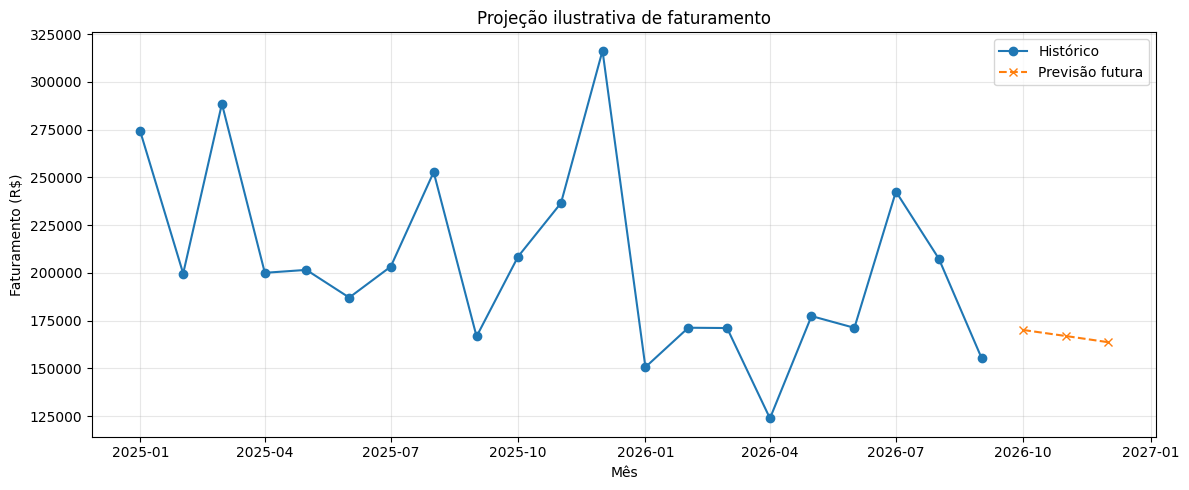

In [30]:

plt.figure(figsize=(12, 5))

plt.plot(
    dados_ml["data"],
    dados_ml["faturamento"],
    label="Histórico",
    marker="o"
)

plt.plot(
    datas_futuras,
    faturamento_previsto,
    label="Previsão futura",
    marker="x",
    linestyle="--"
)

plt.title("Projeção ilustrativa de faturamento")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [31]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Recupera a base tratada, se necessário
if "df_limpo" not in globals():
    arquivo = Path("/content/vendas_tratadas.csv")

    if not arquivo.exists():
        raise FileNotFoundError(
            "Não encontrei vendas_tratadas.csv. "
            "Faça upload do arquivo no Colab ou execute as etapas anteriores."
        )

    df_limpo = pd.read_csv(arquivo, parse_dates=["data"])

# Garante o formato correto das colunas
df_relatorio = df_limpo.copy()
df_relatorio["data"] = pd.to_datetime(
    df_relatorio["data"], errors="coerce"
)
df_relatorio["faturamento"] = pd.to_numeric(
    df_relatorio["faturamento"], errors="coerce"
)
df_relatorio["quantidade"] = pd.to_numeric(
    df_relatorio["quantidade"], errors="coerce"
)

# Remove registros sem informações essenciais para este relatório
df_relatorio = df_relatorio.dropna(
    subset=["data", "faturamento", "quantidade"]
)

print("BASE UTILIZADA NO RELATÓRIO")
print(f"Linhas: {len(df_relatorio):,}")
print(f"Colunas: {len(df_relatorio.columns)}")
print(f"Período: {df_relatorio['data'].min():%d/%m/%Y} a "
      f"{df_relatorio['data'].max():%d/%m/%Y}")
print(f"Duplicatas completas: {df_relatorio.duplicated().sum()}")
print(f"Valores ausentes: {df_relatorio.isna().sum().sum()}")


BASE UTILIZADA NO RELATÓRIO
Linhas: 1,000
Colunas: 12
Período: 01/01/2025 a 30/09/2026
Duplicatas completas: 0
Valores ausentes: 0


In [32]:

faturamento_total = df_relatorio["faturamento"].sum()
quantidade_total = df_relatorio["quantidade"].sum()
numero_vendas = len(df_relatorio)
ticket_medio = (
    faturamento_total / numero_vendas
    if numero_vendas > 0 else 0
)
preco_medio_por_unidade = (
    faturamento_total / quantidade_total
    if quantidade_total > 0 else 0
)

kpis = pd.DataFrame({
    "Indicador": [
        "Número de vendas",
        "Quantidade total vendida",
        "Faturamento total",
        "Ticket médio por venda",
        "Faturamento médio por unidade vendida",
    ],
    "Valor": [
        numero_vendas,
        quantidade_total,
        faturamento_total,
        ticket_medio,
        preco_medio_por_unidade,
    ],
})

display(kpis.style.format({
    "Valor": lambda x: f"{x:,.2f}".replace(",", "X")
        .replace(".", ",").replace("X", ".")
}))


,Indicador,Valor
0,Número de vendas,"1.000,00"
1,Quantidade total vendida,"4.581,00"
2,Faturamento total,"4.305.643,00"
3,Ticket médio por venda,"4.305,64"
4,Faturamento médio por unidade vendida,"939,89"


In [33]:

faturamento_produto = (
    df_relatorio.groupby("produto", as_index=False)
    .agg(
        faturamento=("faturamento", "sum"),
        unidades=("quantidade", "sum"),
        vendas=("id_venda", "count")
    )
    .sort_values("faturamento", ascending=False)
)

faturamento_regiao = (
    df_relatorio.groupby("regiao", as_index=False)
    .agg(faturamento=("faturamento", "sum"))
    .sort_values("faturamento", ascending=False)
)

faturamento_canal = (
    df_relatorio.groupby("canal", as_index=False)
    .agg(faturamento=("faturamento", "sum"))
    .sort_values("faturamento", ascending=False)
)

print("FATURAMENTO POR PRODUTO")
display(faturamento_produto)

print("FATURAMENTO POR REGIÃO")
display(faturamento_regiao)

print("FATURAMENTO POR CANAL")
display(faturamento_canal)


FATURAMENTO POR PRODUTO


,produto,faturamento,unidades,vendas
6,Notebook,1731100.0,518,118
7,Tablet,749160.0,444,91
4,Monitor,527220.0,465,94
2,Impressora,407205.0,483,107
3,Mesa,309562.5,501,107
0,Cadeira,307312.5,432,96
9,Webcam,99537.5,423,94
1,Headset,74970.0,444,100
8,Teclado,73387.5,518,110
5,Mouse,26188.0,353,83


FATURAMENTO POR REGIÃO


,regiao,faturamento
2,Norte,968085.5
0,Centro-Oeste,898538.0
5,Sul,893910.0
4,Sudeste,762704.5
1,Nordeste,756585.0
3,Não informado,25820.0


FATURAMENTO POR CANAL


,canal,faturamento
0,Loja física,1710376.0
2,Site,1586301.0
1,Marketplace,1008966.0


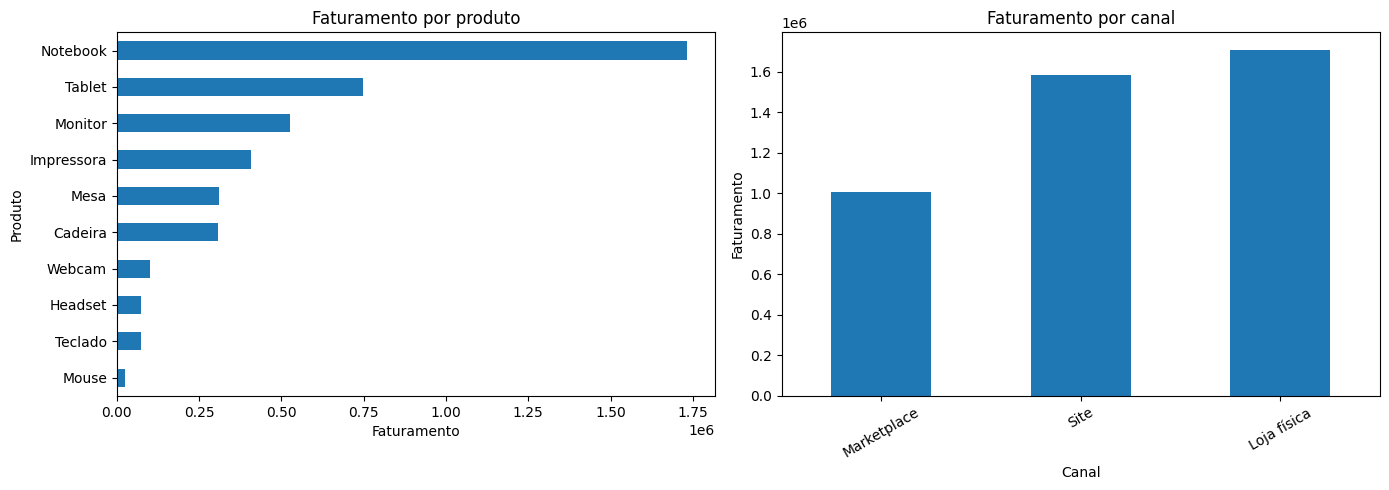

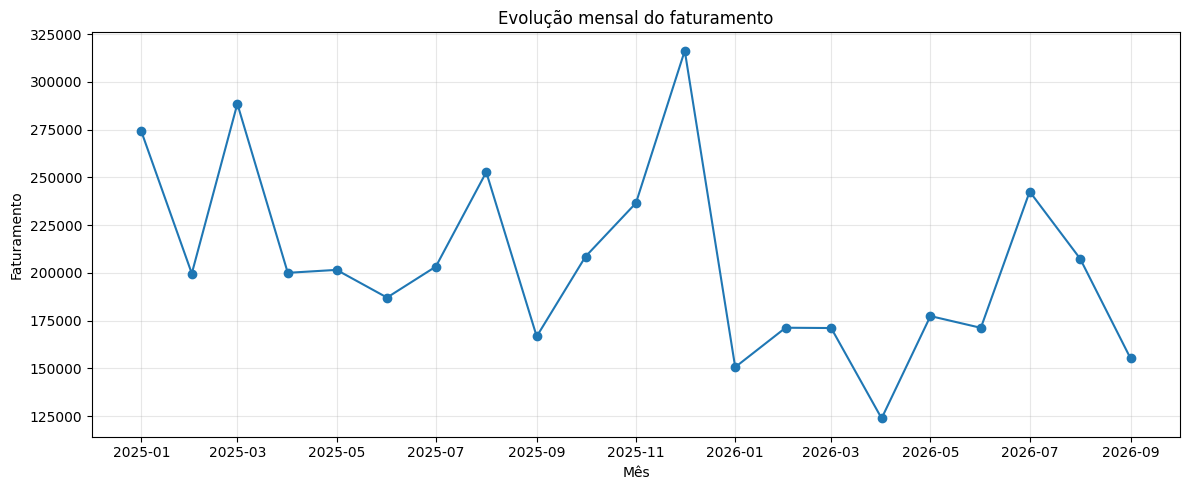

In [34]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

faturamento_produto.sort_values("faturamento").plot(
    x="produto", y="faturamento", kind="barh",
    ax=axes[0], legend=False
)
axes[0].set_title("Faturamento por produto")
axes[0].set_xlabel("Faturamento")
axes[0].set_ylabel("Produto")

faturamento_canal.sort_values("faturamento").plot(
    x="canal", y="faturamento", kind="bar",
    ax=axes[1], legend=False
)
axes[1].set_title("Faturamento por canal")
axes[1].set_xlabel("Canal")
axes[1].set_ylabel("Faturamento")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

faturamento_mensal = (
    df_relatorio.set_index("data")["faturamento"]
    .resample("MS").sum()
)

plt.figure(figsize=(12, 5))
plt.plot(
    faturamento_mensal.index,
    faturamento_mensal.values,
    marker="o"
)
plt.title("Evolução mensal do faturamento")
plt.xlabel("Mês")
plt.ylabel("Faturamento")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,Modelo,MAE,RMSE
0,Regressão linear,33440.96,45922.51
1,Baseline: último mês,66943.90,73747.69


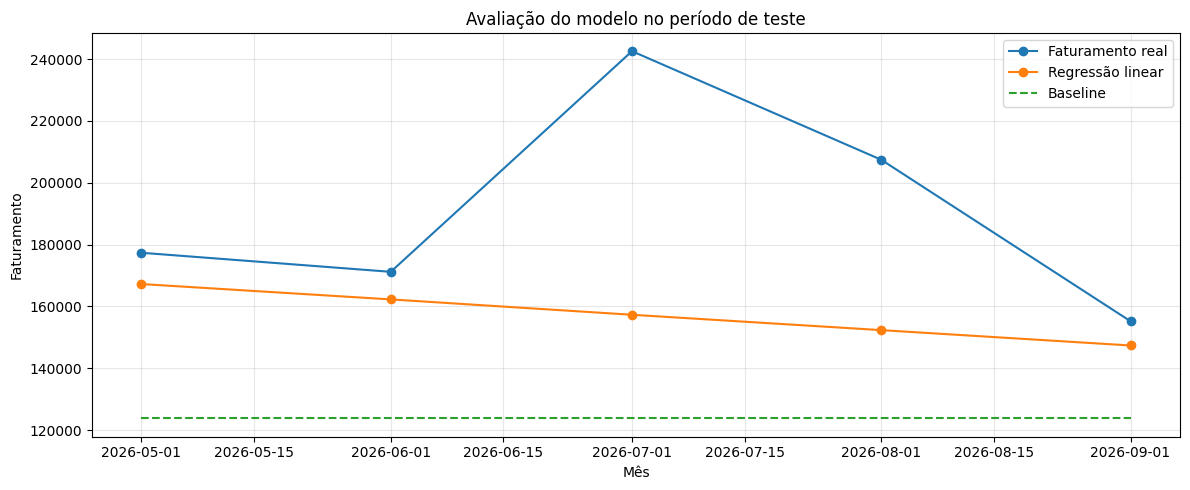

In [35]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Série mensal ordenada no tempo
serie_mensal = (
    df_relatorio.set_index("data")["faturamento"]
    .resample("MS").sum()
    .sort_index()
)

dados_ml = pd.DataFrame({
    "data": serie_mensal.index,
    "faturamento": serie_mensal.values
})
dados_ml["tempo"] = np.arange(len(dados_ml))

if len(dados_ml) < 5:
    raise ValueError(
        "Há poucos meses de dados para uma avaliação temporal útil."
    )

# Divisão temporal: primeiros 80% para treino e últimos 20% para teste
ponto_corte = int(len(dados_ml) * 0.8)
treino = dados_ml.iloc[:ponto_corte]
teste = dados_ml.iloc[ponto_corte:]

modelo_teste = LinearRegression()
modelo_teste.fit(treino[["tempo"]], treino["faturamento"])

previsao_modelo = modelo_teste.predict(teste[["tempo"]])

# Baseline: repetir o último faturamento observado no treino
previsao_baseline = np.repeat(
    treino["faturamento"].iloc[-1], len(teste)
)

metricas = pd.DataFrame({
    "Modelo": ["Regressão linear", "Baseline: último mês"],
    "MAE": [
        mean_absolute_error(teste["faturamento"], previsao_modelo),
        mean_absolute_error(teste["faturamento"], previsao_baseline)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            teste["faturamento"], previsao_modelo
        )),
        np.sqrt(mean_squared_error(
            teste["faturamento"], previsao_baseline
        ))
    ]
})

display(metricas.round(2))

# Gráfico dos resultados no período de teste
plt.figure(figsize=(12, 5))
plt.plot(
    teste["data"], teste["faturamento"],
    marker="o", label="Faturamento real"
)
plt.plot(
    teste["data"], previsao_modelo,
    marker="o", label="Regressão linear"
)
plt.plot(
    teste["data"], previsao_baseline,
    linestyle="--", label="Baseline"
)
plt.title("Avaliação do modelo no período de teste")
plt.xlabel("Mês")
plt.ylabel("Faturamento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,mes,previsao_original,previsao_ajustada
0,2026-10-01,170082.80,170082.80
1,2026-11-01,166905.73,166905.73
2,2026-12-01,163728.66,163728.66


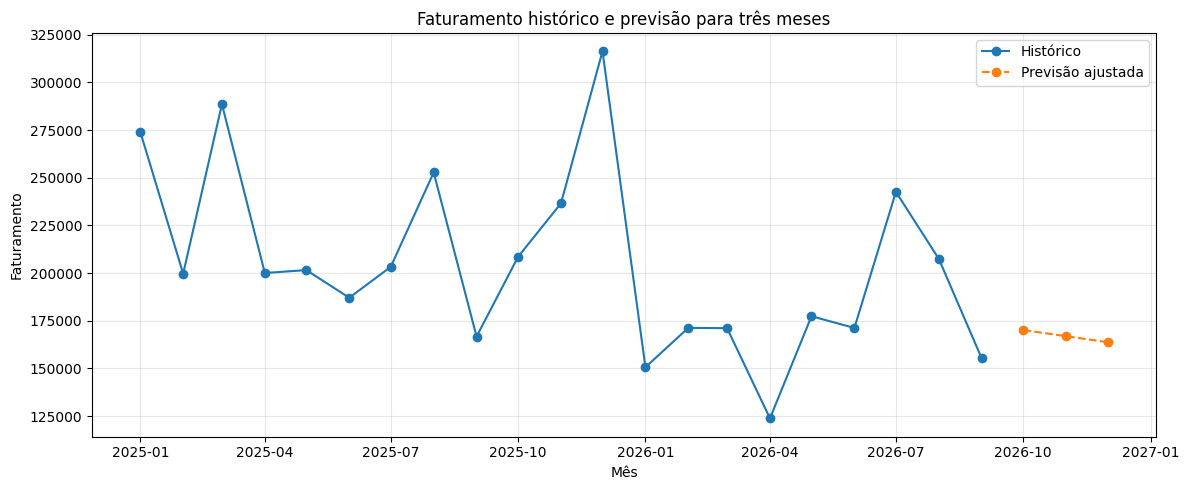

In [36]:

modelo_final = LinearRegression()
modelo_final.fit(dados_ml[["tempo"]], dados_ml["faturamento"])

datas_futuras = pd.date_range(
    start=dados_ml["data"].max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

tempos_futuros = np.arange(
    len(dados_ml), len(dados_ml) + len(datas_futuras)
)

previsoes_brutas = modelo_final.predict(
    pd.DataFrame({"tempo": tempos_futuros})
)

previsoes = pd.DataFrame({
    "mes": datas_futuras,
    "previsao_original": previsoes_brutas,
    "previsao_ajustada": np.maximum(previsoes_brutas, 0)
})

display(previsoes.round(2))

plt.figure(figsize=(12, 5))
plt.plot(
    dados_ml["data"], dados_ml["faturamento"],
    marker="o", label="Histórico"
)
plt.plot(
    previsoes["mes"], previsoes["previsao_ajustada"],
    marker="o", linestyle="--", label="Previsão ajustada"
)
plt.title("Faturamento histórico e previsão para três meses")
plt.xlabel("Mês")
plt.ylabel("Faturamento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [37]:

produto_top = faturamento_produto.iloc[0]
regiao_top = faturamento_regiao.iloc[0]
canal_top = faturamento_canal.iloc[0]

mae_modelo = metricas.loc[
    metricas["Modelo"] == "Regressão linear", "MAE"
].iloc[0]
mae_baseline = metricas.loc[
    metricas["Modelo"] == "Baseline: último mês", "MAE"
].iloc[0]

if mae_modelo < mae_baseline:
    conclusao_modelo = (
        "A regressão linear apresentou MAE menor que o baseline "
        "no período de teste."
    )
elif mae_modelo > mae_baseline:
    conclusao_modelo = (
        "O baseline apresentou MAE menor que a regressão linear "
        "no período de teste."
    )
else:
    conclusao_modelo = (
        "Os dois métodos apresentaram o mesmo MAE no período de teste."
    )

relatorio_texto = f"""
RELATÓRIO EXECUTIVO — VENDAS FICTÍCIAS

1. ESCOPO
Foram analisados {len(df_relatorio)} registros de venda,
entre {df_relatorio['data'].min():%d/%m/%Y} e
{df_relatorio['data'].max():%d/%m/%Y}.

2. INDICADORES
Faturamento total: R$ {faturamento_total:,.2f}
Quantidade total vendida: {quantidade_total:,.0f}
Número de registros de venda: {numero_vendas}
Ticket médio por registro: R$ {ticket_medio:,.2f}

3. DESTAQUES DA AMOSTRA
Produto com maior faturamento: {produto_top['produto']}
Faturamento do produto: R$ {produto_top['faturamento']:,.2f}
Região com maior faturamento: {regiao_top['regiao']}
Canal com maior faturamento: {canal_top['canal']}

4. MODELO PREDITIVO
{conclusao_modelo}
MAE da regressão linear: R$ {mae_modelo:,.2f}
MAE do baseline: R$ {mae_baseline:,.2f}

5. RECOMENDAÇÕES
- Investigar os produtos e canais de maior faturamento.
- Analisar separadamente volume vendido, preço e descontos.
- Repetir a avaliação com dados reais e mais histórico temporal.
- Comparar modelos simples antes de adotar modelos mais complexos.
- Não utilizar as previsões deste exercício para decisões financeiras reais.

LIMITAÇÃO
Os dados são sintéticos. Os padrões e as previsões são ilustrativos
e não demonstram tendências reais de mercado.
"""

print(relatorio_texto)



RELATÓRIO EXECUTIVO — VENDAS FICTÍCIAS

1. ESCOPO
Foram analisados 1000 registros de venda,
entre 01/01/2025 e
30/09/2026.

2. INDICADORES
Faturamento total: R$ 4,305,643.00
Quantidade total vendida: 4,581
Número de registros de venda: 1000
Ticket médio por registro: R$ 4,305.64

3. DESTAQUES DA AMOSTRA
Produto com maior faturamento: Notebook
Faturamento do produto: R$ 1,731,100.00
Região com maior faturamento: Norte
Canal com maior faturamento: Loja física

4. MODELO PREDITIVO
A regressão linear apresentou MAE menor que o baseline no período de teste.
MAE da regressão linear: R$ 33,440.96
MAE do baseline: R$ 66,943.90

5. RECOMENDAÇÕES
- Investigar os produtos e canais de maior faturamento.
- Analisar separadamente volume vendido, preço e descontos.
- Repetir a avaliação com dados reais e mais histórico temporal.
- Comparar modelos simples antes de adotar modelos mais complexos.
- Não utilizar as previsões deste exercício para decisões financeiras reais.

LIMITAÇÃO
Os dados são sinté

In [38]:

# Exportar indicadores e tabelas
kpis.to_csv(
    "/content/relatorio_kpis.csv",
    index=False, encoding="utf-8-sig"
)
faturamento_produto.to_csv(
    "/content/faturamento_por_produto.csv",
    index=False, encoding="utf-8-sig"
)
faturamento_regiao.to_csv(
    "/content/faturamento_por_regiao.csv",
    index=False, encoding="utf-8-sig"
)
faturamento_canal.to_csv(
    "/content/faturamento_por_canal.csv",
    index=False, encoding="utf-8-sig"
)
metricas.to_csv(
    "/content/metricas_modelo.csv",
    index=False, encoding="utf-8-sig"
)
previsoes.to_csv(
    "/content/previsoes_faturamento.csv",
    index=False, encoding="utf-8"
)

with open(
    "/content/relatorio_executivo.txt",
    "w", encoding="utf-8"
) as arquivo:
    arquivo.write(relatorio_texto)

print("Arquivos gerados:")
print("- relatorio_kpis.csv")
print("- faturamento_por_produto.csv")
print("- faturamento_por_regiao.csv")
print("- faturamento_por_canal.csv")
print("- metricas_modelo.csv")
print("- previsoes_faturamento.csv")
print("- relatorio_executivo.txt")


Arquivos gerados:
- relatorio_kpis.csv
- faturamento_por_produto.csv
- faturamento_por_regiao.csv
- faturamento_por_canal.csv
- metricas_modelo.csv
- previsoes_faturamento.csv
- relatorio_executivo.txt


tentativa de rechamada de dados ja que os dados foram perdidos, se nao salvar no drive tera de rodar tudo de novo para gerar os csv de novo.

In [39]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reutilizar a base tratada ou carregar o arquivo
if "df_limpo" not in globals():
    df_limpo = pd.read_csv(
        "/content/vendas_tratadas.csv",
        parse_dates=["data"]
    )

df_modelo = df_limpo.copy()
df_modelo["data"] = pd.to_datetime(df_modelo["data"])
df_modelo["faturamento"] = pd.to_numeric(
    df_modelo["faturamento"], errors="coerce"
)

df_modelo = df_modelo.dropna(
    subset=["data", "faturamento"]
)

# Somar faturamento por mês
serie_mensal = (
    df_modelo.set_index("data")["faturamento"]
    .resample("MS")
    .sum()
    .sort_index()
)

dados_ml = pd.DataFrame({
    "data": serie_mensal.index,
    "faturamento": serie_mensal.values
})

dados_ml["tempo"] = np.arange(len(dados_ml))

display(dados_ml)

print(f"Quantidade de meses disponíveis: {len(dados_ml)}")


,data,faturamento,tempo
0,2025-01-01,274049.0,0
1,2025-02-01,199659.0,1
2,2025-03-01,288527.5,2
3,2025-04-01,200019.5,3
4,2025-05-01,201557.0,4
5,2025-06-01,187059.5,5
6,2025-07-01,203275.0,6
7,2025-08-01,252751.0,7
8,2025-09-01,166698.5,8
9,2025-10-01,208530.5,9


Quantidade de meses disponíveis: 21


In [40]:

if len(dados_ml) < 5:
    raise ValueError(
        "Precisamos de pelo menos 5 meses para esta demonstração."
    )

ponto_corte = int(len(dados_ml) * 0.8)

treino = dados_ml.iloc[:ponto_corte].copy()
teste = dados_ml.iloc[ponto_corte:].copy()

print(f"Meses para treino: {len(treino)}")
print(f"Meses para teste: {len(teste)}")
print(
    f"Período de treino: {treino['data'].min():%Y-%m} "
    f"a {treino['data'].max():%Y-%m}"
)
print(
    f"Período de teste: {teste['data'].min():%Y-%m} "
    f"a {teste['data'].max():%Y-%m}"
)


Meses para treino: 16
Meses para teste: 5
Período de treino: 2025-01 a 2026-04
Período de teste: 2026-05 a 2026-09


In [41]:

# Modelo 1: baseline — repetir o último mês do treino
previsao_baseline = np.repeat(
    treino["faturamento"].iloc[-1],
    len(teste)
)

# Modelo 2: média dos últimos 3 meses do treino
janela = min(3, len(treino))

valor_media_movel = treino["faturamento"].tail(janela).mean()

# Mantemos essa média fixa para todos os meses do teste
previsao_media_movel = np.repeat(
    valor_media_movel,
    len(teste)
)

# Modelo 3: regressão linear baseada no tempo
modelo_linear = LinearRegression()

modelo_linear.fit(
    treino[["tempo"]],
    treino["faturamento"]
)

previsao_linear = modelo_linear.predict(
    teste[["tempo"]]
)

# Comparar as previsões
comparacao = pd.DataFrame({
    "data": teste["data"].values,
    "real": teste["faturamento"].values,
    "baseline": previsao_baseline,
    "media_movel": previsao_media_movel,
    "regressao_linear": previsao_linear
})

display(comparacao.round(2))


,data,real,baseline,media_movel,regressao_linear
0,2026-05-01,177371.5,123819.0,155397.33,167258.58
1,2026-06-01,171212.0,123819.0,155397.33,162290.26
2,2026-07-01,242562.0,123819.0,155397.33,157321.94
3,2026-08-01,207446.5,123819.0,155397.33,152353.62
4,2026-09-01,155222.5,123819.0,155397.33,147385.30


In [42]:

valores_reais = comparacao["real"]

previsoes_modelos = {
    "Baseline": comparacao["baseline"],
    "Média móvel": comparacao["media_movel"],
    "Regressão linear": comparacao["regressao_linear"]
}

resultados = []

for nome, valores_previstos in previsoes_modelos.items():
    mae = mean_absolute_error(
        valores_reais, valores_previstos
    )

    rmse = np.sqrt(mean_squared_error(
        valores_reais, valores_previstos
    ))

    resultados.append({
        "Modelo": nome,
        "MAE": mae,
        "RMSE": rmse
    })

metricas_comparacao = (
    pd.DataFrame(resultados)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(metricas_comparacao.round(2))

melhor_modelo_mae = metricas_comparacao.iloc[0]["Modelo"]

print(
    "Modelo com menor MAE no período de teste:",
    melhor_modelo_mae
)


,Modelo,MAE,RMSE
0,Regressão linear,33440.96,45922.51
1,Média móvel,35435.50,46988.92
2,Baseline,66943.90,73747.69


Modelo com menor MAE no período de teste: Regressão linear


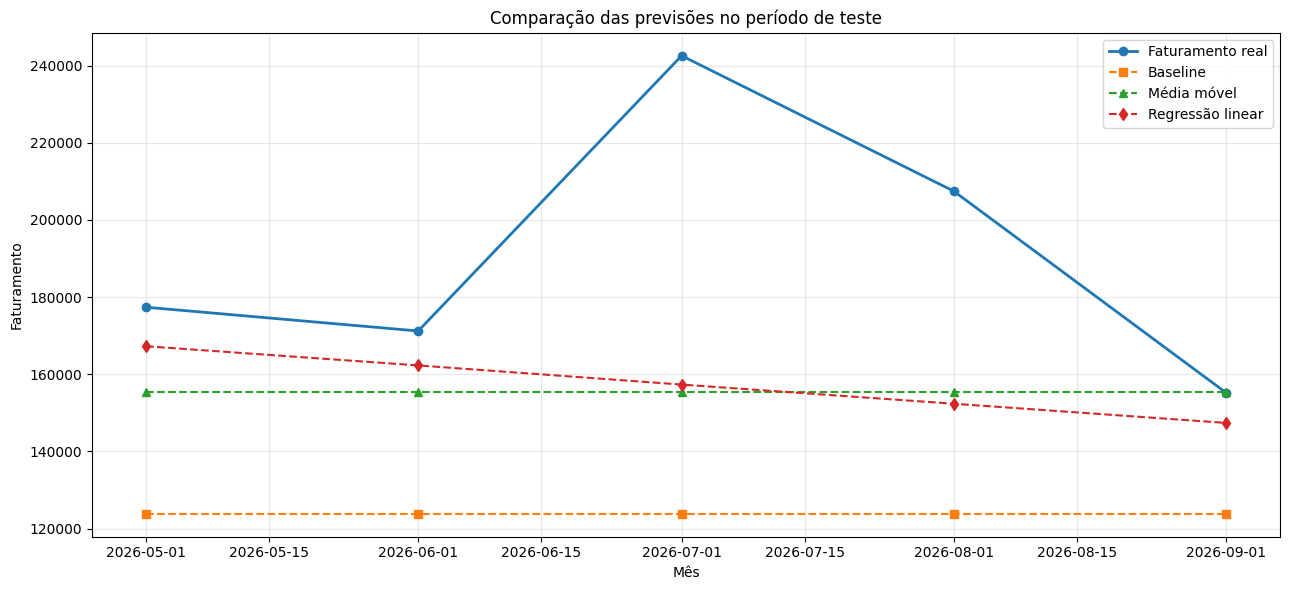

In [43]:

plt.figure(figsize=(13, 6))

plt.plot(
    comparacao["data"],
    comparacao["real"],
    marker="o",
    linewidth=2,
    label="Faturamento real"
)

plt.plot(
    comparacao["data"],
    comparacao["baseline"],
    marker="s",
    linestyle="--",
    label="Baseline"
)

plt.plot(
    comparacao["data"],
    comparacao["media_movel"],
    marker="^",
    linestyle="--",
    label="Média móvel"
)

plt.plot(
    comparacao["data"],
    comparacao["regressao_linear"],
    marker="d",
    linestyle="--",
    label="Regressão linear"
)

plt.title("Comparação das previsões no período de teste")
plt.xlabel("Mês")
plt.ylabel("Faturamento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:

melhor_mae = metricas_comparacao.loc[
    metricas_comparacao["MAE"].idxmin()
]

melhor_rmse = metricas_comparacao.loc[
    metricas_comparacao["RMSE"].idxmin()
]

print("CONCLUSÃO DA COMPARAÇÃO")
print("-" * 35)

print(
    f"Menor MAE: {melhor_mae['Modelo']} "
    f"({melhor_mae['MAE']:.2f})"
)

print(
    f"Menor RMSE: {melhor_rmse['Modelo']} "
    f"({melhor_rmse['RMSE']:.2f})"
)

if melhor_mae["Modelo"] == melhor_rmse["Modelo"]:
    print(
        "\nO mesmo modelo apresentou o menor MAE e RMSE "
        "neste período de teste."
    )
else:
    print(
        "\nAs métricas apontam para modelos diferentes. "
        "Investigue os erros maiores antes de escolher."
    )

print(
    "\nAtenção: esta comparação utiliza poucos dados sintéticos "
    "e um único período de teste. O resultado não garante "
    "o mesmo desempenho no futuro."
)


CONCLUSÃO DA COMPARAÇÃO
-----------------------------------
Menor MAE: Regressão linear (33440.96)
Menor RMSE: Regressão linear (45922.51)

O mesmo modelo apresentou o menor MAE e RMSE neste período de teste.

Atenção: esta comparação utiliza poucos dados sintéticos e um único período de teste. O resultado não garante o mesmo desempenho no futuro.


In [45]:

metricas_comparacao.to_csv(
    "/content/comparacao_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

comparacao.to_csv(
    "/content/previsoes_comparadas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos exportados:")
print("1. comparacao_modelos.csv")
print("2. previsoes_comparadas.csv")


Arquivos exportados:
1. comparacao_modelos.csv
2. previsoes_comparadas.csv


In [46]:

from google.colab import files

files.download("/content/comparacao_modelos.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import plotly.express as px
import plotly.graph_objects as go

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

from sklearn.linear_model import LinearRegression

# Verificar se a base tratada está disponível
caminho = "/content/vendas_tratadas.csv"

if not os.path.exists(caminho):
    from google.colab import files

    print("Envie o arquivo vendas_tratadas.csv")
    arquivos = files.upload()

    if "vendas_tratadas.csv" not in arquivos:
        raise FileNotFoundError(
            "Envie o arquivo vendas_tratadas.csv para continuar."
        )

    caminho = "/content/vendas_tratadas.csv"

# Carregar a base
df_dashboard = pd.read_csv(caminho, parse_dates=["data"])

# Garantir tipos adequados
df_dashboard["data"] = pd.to_datetime(
    df_dashboard["data"], errors="coerce"
)
df_dashboard["faturamento"] = pd.to_numeric(
    df_dashboard["faturamento"], errors="coerce"
)
df_dashboard["quantidade"] = pd.to_numeric(
    df_dashboard["quantidade"], errors="coerce"
)

df_dashboard = df_dashboard.dropna(
    subset=["data", "faturamento", "quantidade"]
).copy()

# Verificar as colunas necessárias
colunas_necessarias = [
    "data", "faturamento", "quantidade",
    "produto", "regiao", "canal"
]

faltantes = [
    coluna for coluna in colunas_necessarias
    if coluna not in df_dashboard.columns
]

if faltantes:
    raise ValueError(
        f"Faltam colunas necessárias: {faltantes}"
    )

print("Base carregada com sucesso!")
print(f"Registros: {len(df_dashboard):,}")
print(
    f"Período: {df_dashboard['data'].min():%d/%m/%Y} "
    f"a {df_dashboard['data'].max():%d/%m/%Y}"
)

display(df_dashboard.head())

Base carregada com sucesso!
Registros: 1,000
Período: 01/01/2025 a 30/09/2026


,id_venda,data,produto,quantidade,regiao,canal,pagamento,tipo_cliente,categoria,preco_unitario,desconto_pct,faturamento
0,1,2026-09-15,Webcam,7,Norte,Marketplace,Cartão de débito,Novo,Acessórios,250.0,0.15,1487.5
1,2,2026-09-08,Monitor,6,Sudeste,Loja física,Cartão de crédito,Novo,Eletrônicos,1200.0,0.00,7200.0
2,3,2026-04-05,Headset,4,Centro-Oeste,Site,Cartão de crédito,Recorrente,Acessórios,180.0,0.05,684.0
3,4,2025-12-22,Impressora,8,Norte,Marketplace,Cartão de crédito,Recorrente,Escritório,900.0,0.15,6120.0
4,5,2025-11-20,Webcam,6,Sul,Site,Cartão de crédito,Novo,Acessórios,250.0,0.05,1425.0


In [48]:
# Opções disponíveis nos filtros
regioes = sorted(
    df_dashboard["regiao"].fillna("Não informado").astype(str).unique()
)

produtos = sorted(
    df_dashboard["produto"].fillna("Não informado").astype(str).unique()
)

canais = sorted(
    df_dashboard["canal"].fillna("Não informado").astype(str).unique()
)

# Datas disponíveis na base
data_minima = df_dashboard["data"].min().date()
data_maxima = df_dashboard["data"].max().date()

# Widgets de data
filtro_inicio = widgets.DatePicker(
    description="Data inicial:",
    value=data_minima
)

filtro_fim = widgets.DatePicker(
    description="Data final:",
    value=data_maxima
)

# Widgets de seleção múltipla
filtro_regiao = widgets.SelectMultiple(
    options=regioes,
    value=tuple(regioes),
    description="Regiões:",
    layout=widgets.Layout(width="300px", height="120px")
)

filtro_produto = widgets.SelectMultiple(
    options=produtos,
    value=tuple(produtos),
    description="Produtos:",
    layout=widgets.Layout(width="300px", height="120px")
)

filtro_canal = widgets.SelectMultiple(
    options=canais,
    value=tuple(canais),
    description="Canais:",
    layout=widgets.Layout(width="300px", height="100px")
)

botao_atualizar = widgets.Button(
    description="Atualizar dashboard",
    button_style="primary",
    icon="refresh"
)

print("Filtros criados!")

Filtros criados!


In [49]:
from IPython.display import display, HTML, clear_output
from sklearn.linear_model import LinearRegression

saida_dashboard = widgets.Output()

def atualizar_dashboard(_=None):

    with saida_dashboard:
        clear_output(wait=True)

        # Validar as datas
        if filtro_inicio.value is None or filtro_fim.value is None:
            print("Selecione as duas datas.")
            return

        inicio = pd.Timestamp(filtro_inicio.value)
        fim = pd.Timestamp(filtro_fim.value)

        if inicio > fim:
            print("A data inicial deve ser anterior à data final.")
            return

        # Criar cópia para aplicar os filtros
        dados = df_dashboard.copy()

        # Padronizar campos categóricos para os filtros
        for coluna in ["regiao", "produto", "canal"]:
            dados[coluna] = (
                dados[coluna]
                .fillna("Não informado")
                .astype(str)
            )

        # Aplicar filtros
        dados = dados[
            (dados["data"] >= inicio) &
            (dados["data"] < fim + pd.Timedelta(days=1)) &
            (dados["regiao"].isin(filtro_regiao.value)) &
            (dados["produto"].isin(filtro_produto.value)) &
            (dados["canal"].isin(filtro_canal.value))
        ].copy()

        if dados.empty:
            print("Nenhuma venda encontrada com esses filtros.")
            return

        # Calcular KPIs
        faturamento = dados["faturamento"].sum()
        unidades = dados["quantidade"].sum()
        numero_vendas = len(dados)
        ticket_medio = faturamento / numero_vendas if numero_vendas else 0

        # Apresentar indicadores
        html_kpis = f"""
        <div style="display:flex; flex-wrap:wrap; gap:12px;">
            <div style="border:1px solid #ddd; padding:16px;
                        border-radius:10px; min-width:180px;">
                <b>Faturamento total</b>
                <h2>R$ {faturamento:,.2f}</h2>
            </div>
            <div style="border:1px solid #ddd; padding:16px;
                        border-radius:10px; min-width:180px;">
                <b>Unidades vendidas</b>
                <h2>{unidades:,.0f}</h2>
            </div>
            <div style="border:1px solid #ddd; padding:16px;
                        border-radius:10px; min-width:180px;">
                <b>Número de vendas</b>
                <h2>{numero_vendas:,}</h2>
            </div>
            <div style="border:1px solid #ddd; padding:16px;
                        border-radius:10px; min-width:180px;">
                <b>Ticket médio</b>
                <h2>R$ {ticket_medio:,.2f}</h2>
            </div>
        </div>
        """

        display(HTML(html_kpis))

        # Faturamento mensal
        mensal = (
            dados.set_index("data")["faturamento"]
            .resample("MS")
            .sum()
            .reset_index()
        )

        fig_mensal = px.line(
            mensal,
            x="data",
            y="faturamento",
            markers=True,
            title="Evolução mensal do faturamento"
        )
        fig_mensal.update_layout(
            xaxis_title="Mês",
            yaxis_title="Faturamento (R$)"
        )
        fig_mensal.show()

        # Faturamento por produto
        por_produto = (
            dados.groupby("produto", as_index=False)
            .agg(faturamento=("faturamento", "sum"))
            .sort_values("faturamento", ascending=False)
        )

        fig_produto = px.bar(
            por_produto,
            x="produto",
            y="faturamento",
            title="Faturamento por produto"
        )
        fig_produto.update_layout(
            xaxis_title="Produto",
            yaxis_title="Faturamento (R$)"
        )
        fig_produto.show()

        # Faturamento por região
        por_regiao = (
            dados.groupby("regiao", as_index=False)
            .agg(faturamento=("faturamento", "sum"))
            .sort_values("faturamento", ascending=False)
        )

        fig_regiao = px.bar(
            por_regiao,
            x="regiao",
            y="faturamento",
            title="Faturamento por região"
        )
        fig_regiao.update_layout(
            xaxis_title="Região",
            yaxis_title="Faturamento (R$)"
        )
        fig_regiao.show()

        # Faturamento por canal
        por_canal = (
            dados.groupby("canal", as_index=False)
            .agg(faturamento=("faturamento", "sum"))
            .sort_values("faturamento", ascending=False)
        )

        fig_canal = px.pie(
            por_canal,
            names="canal",
            values="faturamento",
            title="Participação dos canais no faturamento"
        )
        fig_canal.show()

        # Previsão mensal ilustrativa
        serie = (
            dados.set_index("data")["faturamento"]
            .resample("MS")
            .sum()
            .sort_index()
        )

        if len(serie) >= 3:

            X = np.arange(len(serie)).reshape(-1, 1)
            y = serie.values

            modelo = LinearRegression()
            modelo.fit(X, y)

            # Próximos três meses após o último mês da série
            X_futuro = np.arange(
                len(serie), len(serie) + 3
            ).reshape(-1, 1)

            previsoes_futuras = modelo.predict(X_futuro)

            # Ajuste para evitar exibir faturamento negativo
            previsoes_ajustadas = np.maximum(
                previsoes_futuras, 0
            )

            datas_futuras = pd.date_range(
                start=serie.index[-1] + pd.offsets.MonthBegin(1),
                periods=3,
                freq="MS"
            )

            tabela_previsao = pd.DataFrame({
                "Mês": datas_futuras,
                "Previsão original": previsoes_futuras,
                "Previsão ajustada": previsoes_ajustadas
            })

            print(
                "PREVISÃO ILUSTRATIVA — REGRESSÃO LINEAR"
            )
            display(tabela_previsao.round(2))

            fig_previsao = go.Figure()

            fig_previsao.add_trace(go.Scatter(
                x=serie.index,
                y=serie.values,
                mode="lines+markers",
                name="Histórico"
            ))

            fig_previsao.add_trace(go.Scatter(
                x=datas_futuras,
                y=previsoes_ajustadas,
                mode="lines+markers",
                name="Previsão ajustada",
                line=dict(dash="dash")
            ))

            fig_previsao.update_layout(
                title="Histórico e previsão de faturamento",
                xaxis_title="Mês",
                yaxis_title="Faturamento (R$)"
            )

            fig_previsao.show()

            print(
                "A previsão é ilustrativa. Ela usa regressão linear "
                "sobre os meses filtrados e não deve ser tratada como "
                "garantia de faturamento futuro."
            )

        else:
            print(
                "São necessários pelo menos três meses no período "
                "selecionado para gerar esta previsão ilustrativa."
            )

        # Resumo dos filtros aplicados
        print("\nRESUMO DA ANÁLISE")
        print(f"Período: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y}")
        print(f"Registros analisados: {len(dados):,}")

# Conectar o botão à função
botao_atualizar.on_click(atualizar_dashboard)

# Organizar a interface
linha_datas = widgets.HBox([filtro_inicio, filtro_fim])
linha_categorias = widgets.HBox([
    filtro_regiao,
    filtro_produto,
    filtro_canal
])

display(HTML("<h2>Dashboard de Vendas</h2>"))
display(linha_datas)
display(linha_categorias)
display(botao_atualizar)
display(saida_dashboard)

# Mostrar o primeiro dashboard automaticamente
atualizar_dashboard()

Button(button_style='primary', description='Atualizar dashboard', icon='refresh', style=ButtonStyle())

Output()

In [50]:
botao_exportar = widgets.Button(
    description="Exportar vendas filtradas",
    button_style="success",
    icon="download"
)

def exportar_vendas(_):
    if filtro_inicio.value is None or filtro_fim.value is None:
        print("Selecione as datas antes de exportar.")
        return

    inicio = pd.Timestamp(filtro_inicio.value)
    fim = pd.Timestamp(filtro_fim.value)

    if inicio > fim:
        print("A data inicial deve ser anterior à data final.")
        return

    dados = df_dashboard.copy()

    for coluna in ["regiao", "produto", "canal"]:
        dados[coluna] = (
            dados[coluna].fillna("Não informado").astype(str)
        )

    dados = dados[
        (dados["data"] >= inicio) &
        (dados["data"] < fim + pd.Timedelta(days=1)) &
        (dados["regiao"].isin(filtro_regiao.value)) &
        (dados["produto"].isin(filtro_produto.value)) &
        (dados["canal"].isin(filtro_canal.value))
    ]

    arquivo_saida = "/content/vendas_filtradas_dashboard.csv"

    dados.to_csv(
        arquivo_saida,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Arquivo criado com {len(dados)} registros.")

    from google.colab import files
    files.download(arquivo_saida)

botao_exportar.on_click(exportar_vendas)
display(botao_exportar)

Button(button_style='success', description='Exportar vendas filtradas', icon='download', style=ButtonStyle())

Arquivo criado com 8 registros.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
from pathlib import Path
import shutil
import os

# Pasta principal do projeto
PROJETO = Path("/content/projeto-analise-vendas")

# Criar estrutura de pastas
pastas = [
    PROJETO / "notebooks",
    PROJETO / "data",
    PROJETO / "resultados",
    PROJETO / "imagens",
]

for pasta in pastas:
    pasta.mkdir(parents=True, exist_ok=True)

# Arquivos de dados
arquivos_data = [
    "vendas_ficticias.csv",
    "vendas_tratadas.csv",
]

# Resultados gerados nas etapas anteriores
arquivos_resultados = [
    "relatorio_kpis.csv",
    "faturamento_por_produto.csv",
    "faturamento_por_regiao.csv",
    "faturamento_por_canal.csv",
    "metricas_modelo.csv",
    "comparacao_modelos.csv",
    "previsoes_comparadas.csv",
    "previsoes_faturamento.csv",
    "relatorio_executivo.txt",
]

# Copiar apenas os arquivos que existem
for nome in arquivos_data:
    origem = Path("/content") / nome
    if origem.exists():
        shutil.copy2(origem, PROJETO / "data" / nome)
        print("Dados copiados:", nome)

for nome in arquivos_resultados:
    origem = Path("/content") / nome
    if origem.exists():
        shutil.copy2(origem, PROJETO / "resultados" / nome)
        print("Resultado copiado:", nome)

print("\nEstrutura criada em:", PROJETO)

Dados copiados: vendas_ficticias.csv
Dados copiados: vendas_tratadas.csv
Resultado copiado: relatorio_kpis.csv
Resultado copiado: faturamento_por_produto.csv
Resultado copiado: faturamento_por_regiao.csv
Resultado copiado: faturamento_por_canal.csv
Resultado copiado: metricas_modelo.csv
Resultado copiado: comparacao_modelos.csv
Resultado copiado: previsoes_comparadas.csv
Resultado copiado: previsoes_faturamento.csv
Resultado copiado: relatorio_executivo.txt

Estrutura criada em: /content/projeto-analise-vendas


In [52]:
from pathlib import Path

readme = r"""# Análise de Vendas e Previsão de Faturamento com Python

## Sobre o projeto

Este projeto demonstra um fluxo de Ciência de Dados com dados fictícios de vendas, incluindo limpeza, análise exploratória, comparação de métodos de previsão e dashboard interativo.

**Os dados são sintéticos e os resultados são exclusivamente educacionais.**

## Objetivos

- Limpar e validar dados tabulares.
- Calcular indicadores de negócio.
- Analisar faturamento por produto, região, canal e mês.
- Comparar métodos de previsão mensal.
- Avaliar os modelos com MAE e RMSE.
- Construir um dashboard interativo.

## Ferramentas

Python, Pandas, NumPy, Matplotlib, Plotly, Scikit-learn, IPython Widgets e Google Colab.

## Metodologia

1. Geração dos dados.
2. Inspeção e limpeza.
3. Análise exploratória.
4. Modelagem preditiva.
5. Comparação dos modelos com divisão temporal.
6. Dashboard e relatório executivo.

## Modelos comparados

- Baseline: repetir o último faturamento observado no treino.
- Média móvel: média dos últimos três meses de treino.
- Regressão linear: tendência estimada a partir do tempo.

As métricas MAE e RMSE são usadas para comparar os erros no período de teste.

## Limitações

A base é fictícia, o histórico é curto e os resultados não representam tendências reais de mercado. As previsões são ilustrativas e não devem ser usadas para decisões financeiras.

## Como executar

1. Abra o notebook no Google Colab.
2. Carregue os arquivos CSV necessários.
3. Execute as células em ordem.
4. Consulte as métricas, os gráficos e o dashboard.

## Próximas melhorias

- Avaliação em múltiplos períodos temporais.
- Testes automatizados de qualidade.
- Comparação de outros modelos.
- Melhor organização do código.
- Publicação do dashboard.
"""

caminho_readme = Path("/content/projeto-analise-vendas/README.md")
caminho_readme.write_text(readme, encoding="utf-8")

print("README criado em:", caminho_readme)

README criado em: /content/projeto-analise-vendas/README.md
